In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

In [11]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

D.2 Experiment: choosing λ by cross-validation

Same process as C.2 with N = 200 training points (seed 407), test set of 2000 points, 

candidates $\log_{10}\lambda \in \{0, -2, -4, -6, -8\}$, 

5-fold CV with 40 points per fold.

In [12]:
DEGREE = 10
NOISE_STD = 0.2

def make_sin_data(N, rng):
    """x ~ Uniform[-1, 1], y = sin(pi x) + noise with std 0.2."""
    x = rng.uniform(-1, 1, N)
    y = np.sin(np.pi * x) + NOISE_STD * rng.standard_normal(N)
    return x, y

def poly_raw(x, degree=DEGREE):
    """Columns x^1, ..., x^degree. The constant column is added after scaling."""
    return np.column_stack([x ** k for k in range(1, degree + 1)])

def fit_scaler(x):
    """Mean and std of each polynomial column, computed on TRAINING inputs only."""
    P = poly_raw(x)
    return P.mean(axis=0), P.std(axis=0)

def features(x, scaler):
    """z = (1, standardized x, ..., standardized x^10). The constant 1 is not
    standardized, because its std is 0."""
    mu, sd = scaler
    return add_bias((poly_raw(x) - mu) / sd)

def ridge(Z, y, lam):
    """w_reg = (Z^T Z + lam I)^(-1) Z^T y, from C.1(b). np.linalg.solve is more
    accurate than forming the inverse explicitly."""
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

In [13]:
rng = np.random.default_rng(SEED)
N, N_test = 200, 2000
x_tr, y_tr = make_sin_data(N, rng)
x_te, y_te = make_sin_data(N_test, rng)

log_lams = [0, -2, -4, -6, -8]

def cv_error(x, y, lam, kfold):
    """Average validation MSE over the folds. Scaling uses the training folds only."""
    errs = []
    for tr_idx, va_idx in kfold.split(x):
        sc = fit_scaler(x[tr_idx])
        w = ridge(features(x[tr_idx], sc), y[tr_idx], lam)
        errs.append(mse(y[va_idx], features(x[va_idx], sc) @ w))
    return np.mean(errs)

def test_error(lam):
    """Train on all 200 points, evaluate on the 2000-point test set."""
    sc = fit_scaler(x_tr)
    w = ridge(features(x_tr, sc), y_tr, lam)
    return mse(y_te, features(x_te, sc) @ w)

D.2(a) 5-fold Ecv and Etest

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
print("fold sizes:", [len(va) for _, va in kf.split(x_tr)])

cv_df = pd.DataFrame({
    "log10 lambda": log_lams,
    "Ecv": [cv_error(x_tr, y_tr, 10.0 ** ll, kf) for ll in log_lams],
    "Etest": [test_error(10.0 ** ll) for ll in log_lams],
})
cv_df.style.format({"Ecv": "{:.5f}", "Etest": "{:.5f}"})

fold sizes: [40, 40, 40, 40, 40]


,log10 lambda,Ecv,Etest
0,0,0.04277,0.04434
1,-2,0.03928,0.04203
2,-4,0.04362,0.04218
3,-6,0.04526,0.04228
4,-8,0.04528,0.04228


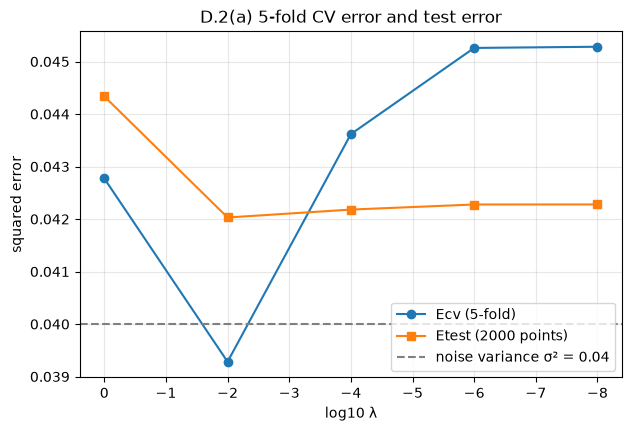

In [15]:
fig, ax = new_ax("log10 λ", "squared error", "D.2(a) 5-fold CV error and test error")
ax.plot(cv_df["log10 lambda"], cv_df["Ecv"], "o-", label="Ecv (5-fold)")
ax.plot(cv_df["log10 lambda"], cv_df["Etest"], "s-", label="Etest (2000 points)")
ax.axhline(NOISE_STD**2, ls="--", c="gray", label="noise variance σ² = 0.04")
ax.invert_xaxis()
ax.legend(); fig.savefig("D2a_cv.png", dpi=150)

D.2(b) λ selected by CV versus λ that minimizes Etest

In [16]:
ll_cv = int(cv_df.loc[cv_df["Ecv"].idxmin(), "log10 lambda"])
ll_test = int(cv_df.loc[cv_df["Etest"].idxmin(), "log10 lambda"])
print(f"CV selects log10 lambda = {ll_cv}")
print(f"Etest is smallest at log10 lambda = {ll_test}")
print("Same choice:", ll_cv == ll_test)

CV selects log10 lambda = -2
Etest is smallest at log10 lambda = -2
Same choice: True


D.2(c) 20 different shuffles

In [17]:
n_shuffles = 20
choices, all_cv = [], []
for s in range(n_shuffles):
    kf_s = KFold(n_splits=5, shuffle=True, random_state=SEED + s)
    ecv = [cv_error(x_tr, y_tr, 10.0 ** ll, kf_s) for ll in log_lams]
    all_cv.append(ecv)
    choices.append(log_lams[int(np.argmin(ecv))])

counts = pd.Series(choices).value_counts().reindex(log_lams, fill_value=0)
sel_df = pd.DataFrame({"log10 lambda": log_lams, "times selected (of 20)": counts.values})
sel_df

,log10 lambda,times selected (of 20)
0,0,0
1,-2,19
2,-4,1
3,-6,0
4,-8,0


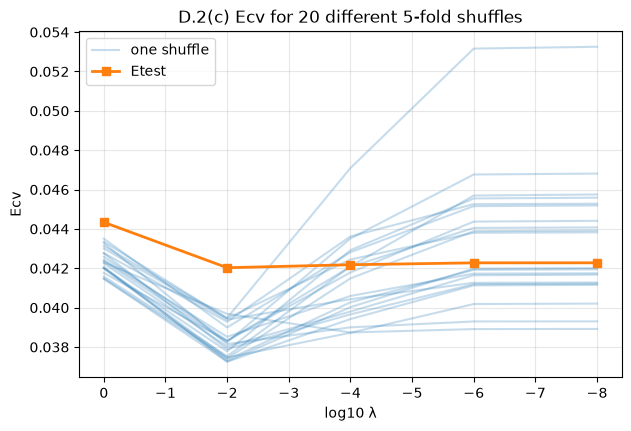

In [18]:
all_cv = np.array(all_cv)
fig, ax = new_ax("log10 λ", "Ecv", "D.2(c) Ecv for 20 different 5-fold shuffles")
for s in range(n_shuffles):
    ax.plot(log_lams, all_cv[s], "-", c="C0", alpha=0.25, label="one shuffle" if s == 0 else None)
ax.plot(log_lams, cv_df["Etest"], "s-", c="C1", lw=2, label="Etest")
ax.invert_xaxis()
ax.legend(); fig.savefig("D2c_shuffles.png", dpi=150)

λ = 10^-2 is selected in 19 of the 20 shuffles, and λ = 10^-4 in 1. So for these candidates a single 5-fold run is fairly reliable. 

Still, the E_cv of one candidate changes a lot from shuffle to shuffle: for λ = 10^-4 it ranges from 0.0387 to 0.0471. When two candidates are close, the selected λ can depend on how the data was shuffled.